# **Exploratory Data Analysis**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Load the dataset
data_path = '/content/drive/MyDrive/Machine_Learning/Final_Project/energydata_complete.csv'
df = pd.read_csv(data_path)

# Convert the 'date' column to datetime and set it as the index
df['date'] = pd.to_datetime(df['date'])
df.set_index('date', inplace=True)


missing_values = df.isnull().sum()



print(missing_values)
print(df.shape)

Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64
(19735, 28)


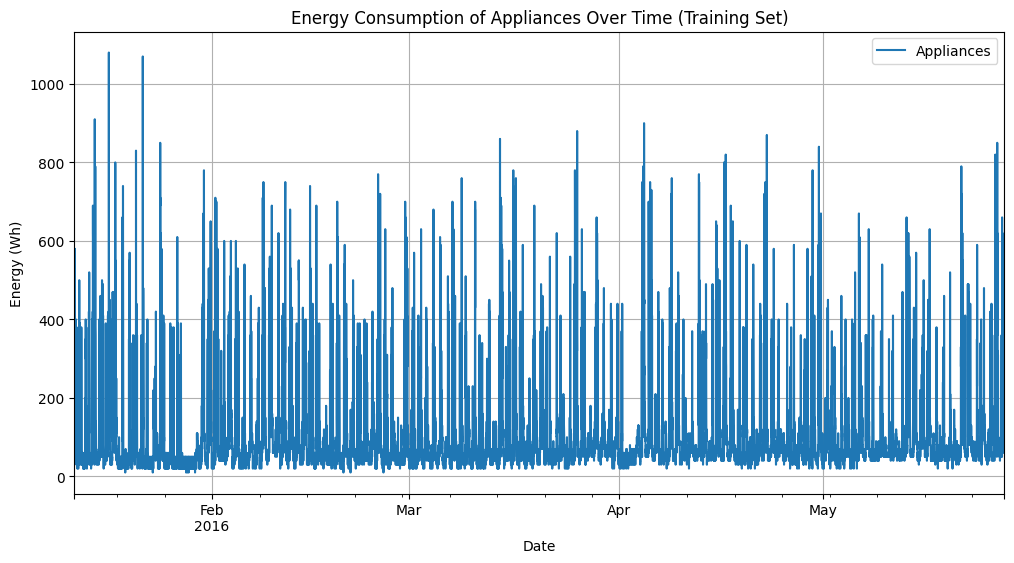

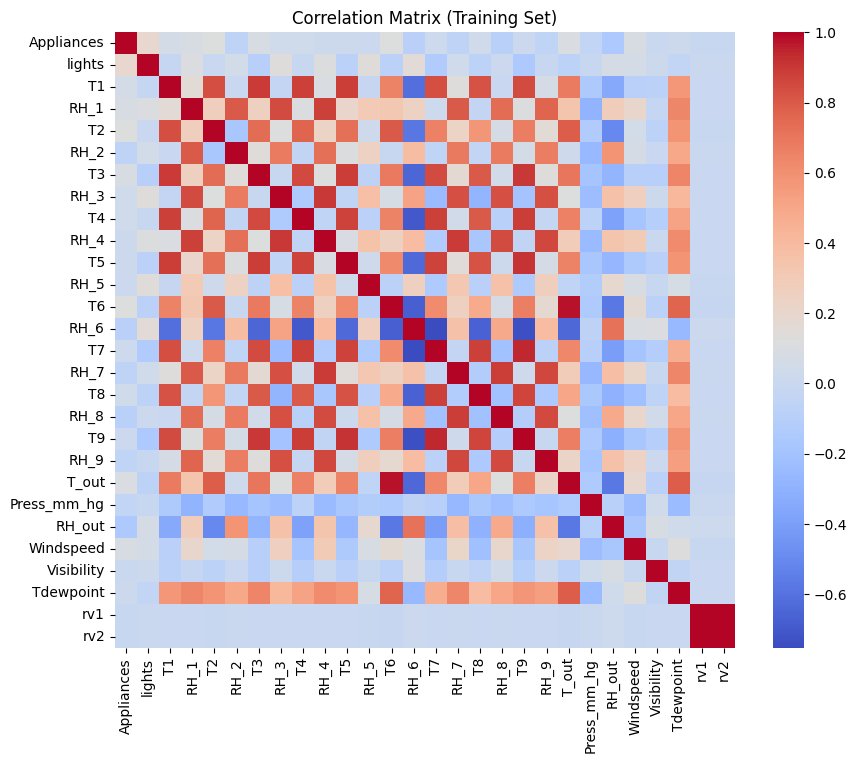

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
count,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,...,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000
mean,97.694958,3.801875,21.686571,40.259739,20.341219,40.420420,22.267611,39.242500,20.855335,39.026904,...,19.485828,41.552401,7.411665,755.522602,79.750418,4.039752,38.330834,3.760707,24.988033,24.988033
std,102.524891,7.935988,1.606066,3.979299,2.192974,4.069813,2.006111,3.254576,2.042884,4.341321,...,2.014712,4.151497,5.317409,7.399441,14.901088,2.451221,11.794719,4.194648,14.496634,14.496634
min,10.000000,0.000000,16.790000,27.023333,16.100000,20.463333,17.200000,28.766667,15.100000,27.660000,...,14.890000,29.166667,-5.000000,729.300000,24.000000,0.000000,1.000000,-6.600000,0.005322,0.005322
25%,50.000000,0.000000,20.760000,37.333333,18.790000,37.900000,20.790000,36.900000,19.530000,35.530000,...,18.000000,38.500000,3.666667,750.933333,70.333333,2.000000,29.000000,0.900000,12.497889,12.497889
50%,60.000000,0.000000,21.600000,39.656667,20.000000,40.500000,22.100000,38.530000,20.666667,38.400000,...,19.390000,40.900000,6.916667,756.100000,83.666667,3.666667,40.000000,3.433333,24.897653,24.897653
75%,100.000000,0.000000,22.600000,43.066667,21.500000,43.260000,23.290000,41.760000,22.100000,42.156667,...,20.600000,44.338095,10.408333,760.933333,91.666667,5.500000,40.000000,6.566667,37.583769,37.583769
max,1080.000000,70.000000,26.260000,63.360000,29.856667,56.026667,29.236000,50.163333,26.200000,51.090000,...,24.500000,53.326667,26.100000,772.300000,100.000000,14.000000,66.000000,15.500000,49.996530,49.996530


In [ ]:
summary = df.describe()

plt.figure(figsize=(12, 6))
df['Appliances'].plot(title="Energy Consumption of Appliances Over Time (Training Set)", ylabel="Energy (Wh)", xlabel="Date", legend=True)
plt.grid()
plt.show()

import seaborn as sns
plt.figure(figsize=(10, 8))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", fmt=".2f", cbar=True)
plt.title("Correlation Matrix (Training Set)")
plt.show()

# Displaying the summary statistics
summary

<Axes: title={'center': 'Appliances for January'}, xlabel='date'>

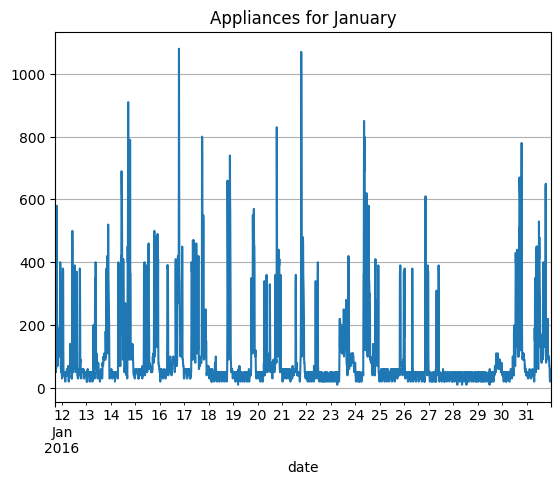

In [ ]:
df_jan = df.loc['2016-01-01':'2016-01-31']
appliance_jan = df_jan['Appliances']
appliance_jan.plot(grid = True, title = 'Appliances for January')

We observe that 27-30 the devices wheren't used. Maybe, because they weren't home

<Axes: title={'center': 'Appliances for February'}, xlabel='date'>

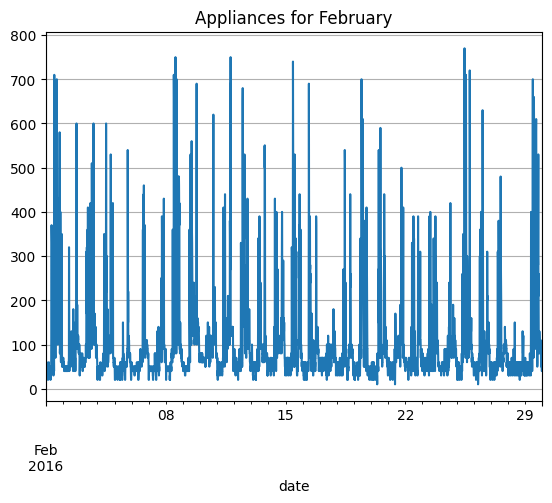

In [ ]:
df_feb = df.loc['2016-02-01':'2016-02-29']
appliance_feb = df_feb['Appliances']
appliance_feb.plot(grid = True, title = 'Appliances for February')

<Axes: title={'center': 'Appliances for March'}, xlabel='date'>

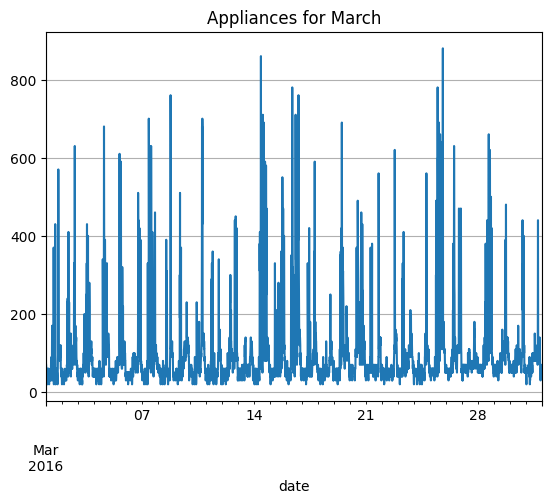

In [ ]:
df_mar = df.loc['2016-03-01':'2016-03-31']
appliance_mar = df_mar['Appliances']
appliance_mar.plot(grid = True, title = 'Appliances for March')

In [ ]:
import plotly.express as px
fig = px.line(df, x=df.index, y="Appliances", title = 'Appliances Slider')

fig.update_xaxes(
    rangeslider_visible= True,
    rangeselector=dict(
                        buttons = list([
                        dict(step= 'all')
                            ])
                        )
                   )
fig.show()

In [ ]:
df = df.drop(['rv1', 'rv2'], axis=1)
df.columns

Index(['Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4',
       'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9',
       'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility',
       'Tdewpoint'],
      dtype='object')

# Plotting the average Applications energy usage per day for each month + every 2 months

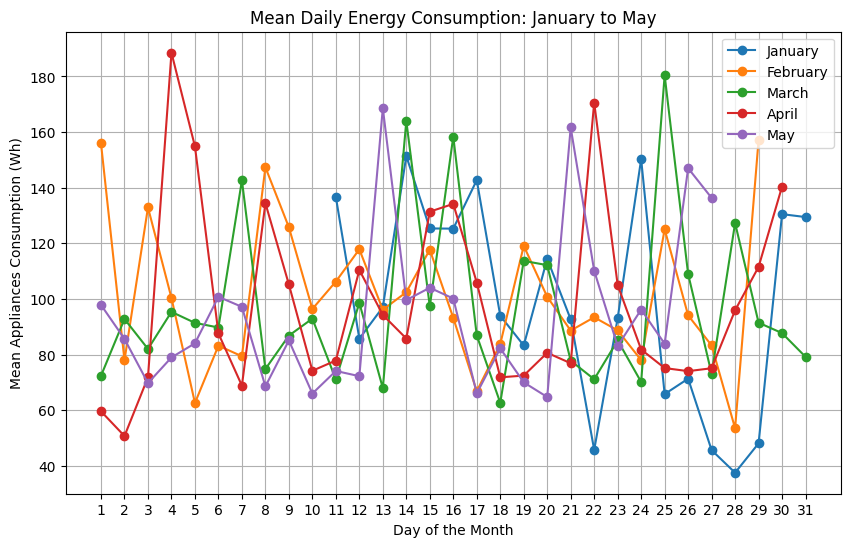

In [ ]:
import matplotlib.pyplot as plt

def plot_months_single_plot(data, target_column='Appliances'):

    data['month'] = data.index.month
    data['day'] = data.index.day

    month_names = ['January', 'February', 'March', 'April', 'May']
    months = [1, 2, 3, 4, 5]

    # Calculate the mean consumption per (month, day)
    daily_mean = data.groupby(['month', 'day'])[target_column].mean().reset_index()

    plt.figure(figsize=(10, 6))

    for month in months:
        subset = daily_mean[daily_mean['month'] == month]
        plt.plot(
            subset['day'],
            subset[target_column],
            label=month_names[month - 1],
            marker='o'
        )

    plt.xlabel("Day of the Month")
    plt.ylabel(f"Mean {target_column} Consumption (Wh)")
    plt.title("Mean Daily Energy Consumption: January to May")
    plt.xticks(range(1, 32))
    plt.grid(True)
    plt.legend()
    plt.show()

plot_months_single_plot(df, target_column='Appliances')

1. Every Month Swings Wildly

 * All five months show big daily fluctuations (from as low as ~60 Wh up to 180+ Wh), so there’s no single month that’s constantly higher or lower. Instead, each line jumps around quite a bit.

2. No Obvious Seasonal Pattern
 * If we look at a single day of the month across all five months, we often see some months are high while others are low. There’s no consistent pattern like “all months increase near day 10.” Rather, the peaks and valleys vary by month.

3. Some Shared Peak Regions
 * We’ll notice clusters where multiple months have relatively high usage on or near the same day (e.g., days 2–3 or days 12–14 or around days 21–23). This might hint at recurring events (weekends or similar occupant routines), or perhaps random coincidence.

4. Hard to Pinpoint a Single Cause
 * Given the day‐to‐day variability, the spikes likely come from short‐term changes—like heavier appliance use, cooking, entertaining, laundry, or weather shifts on specific days.

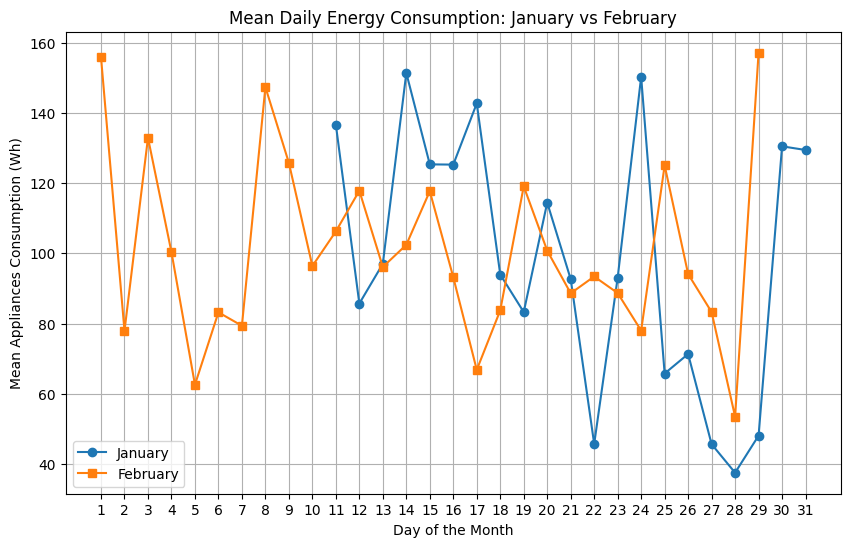

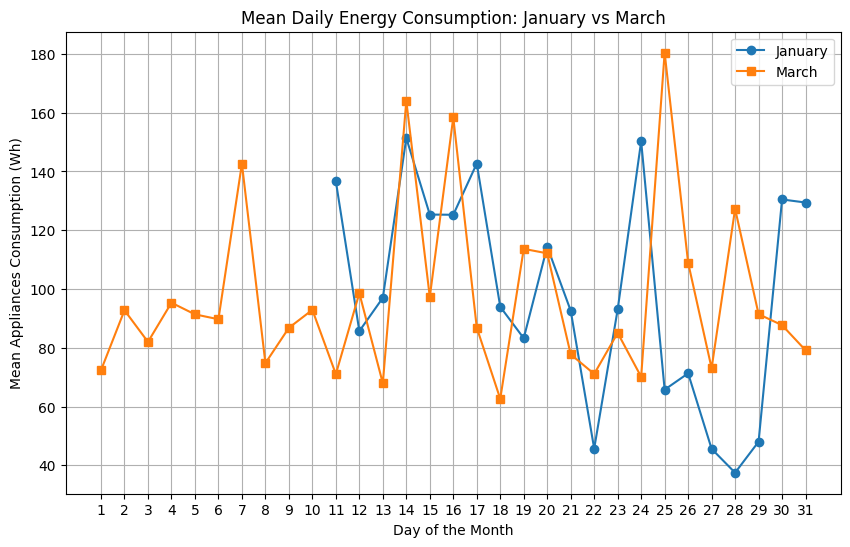

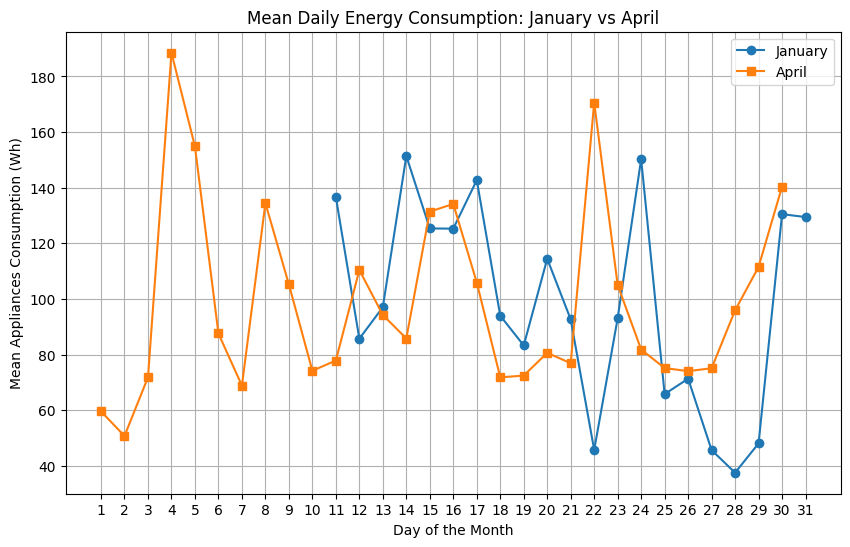

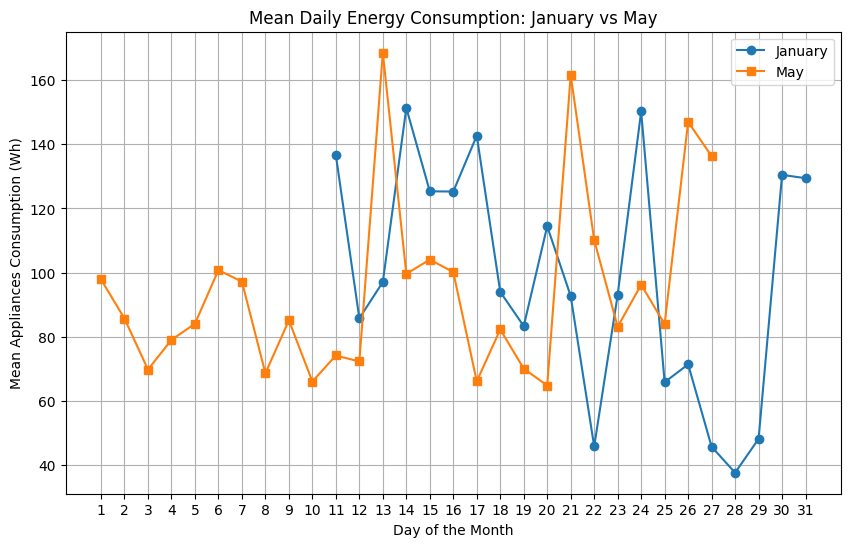

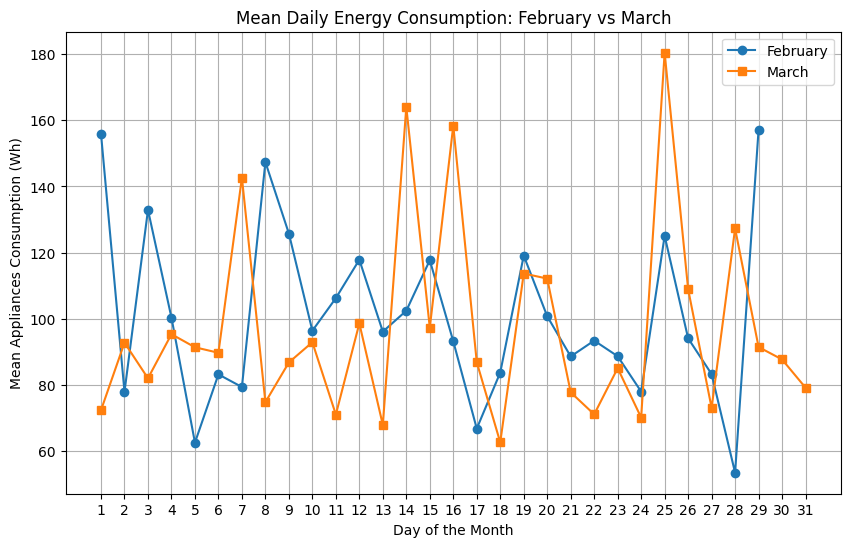

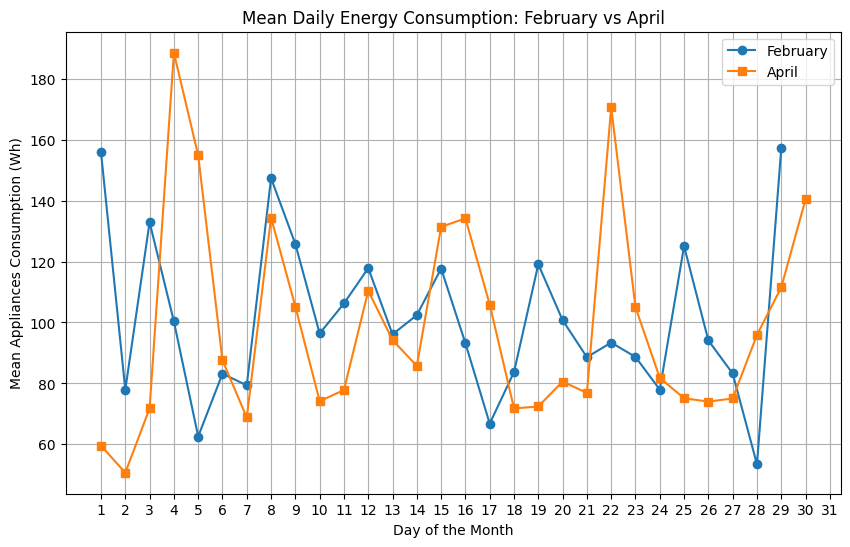

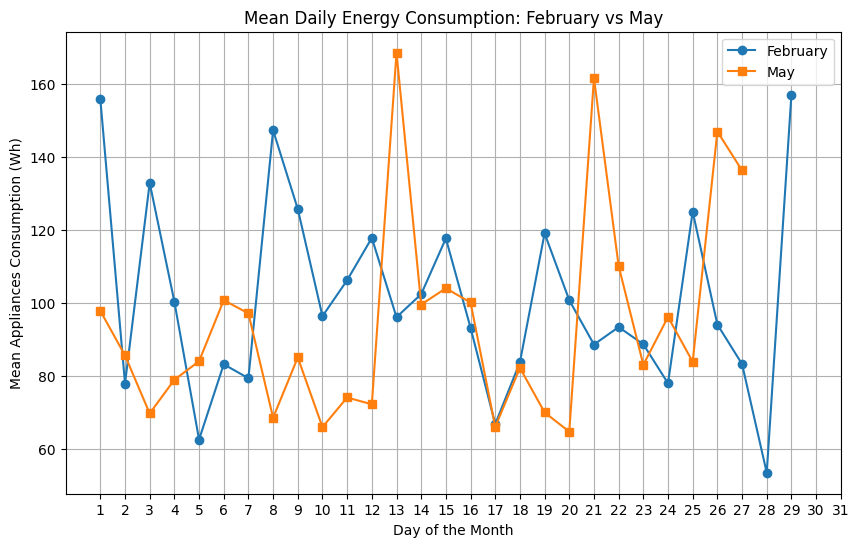

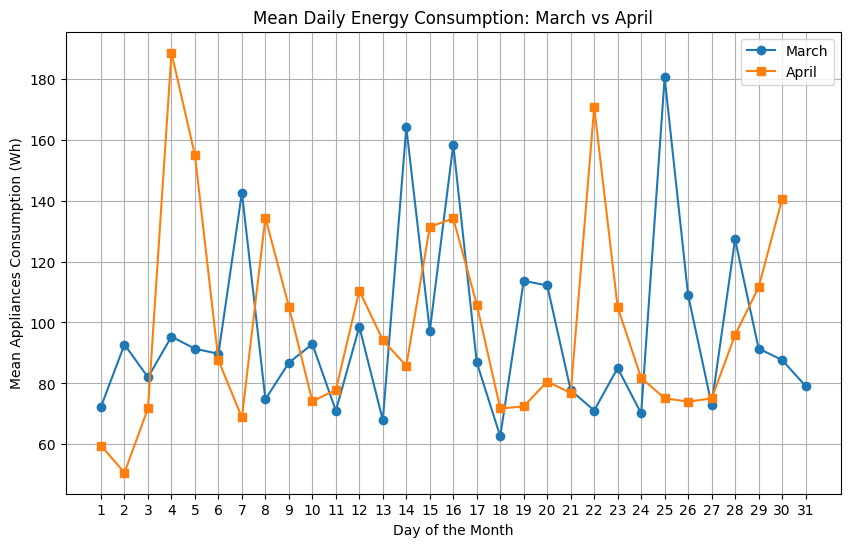

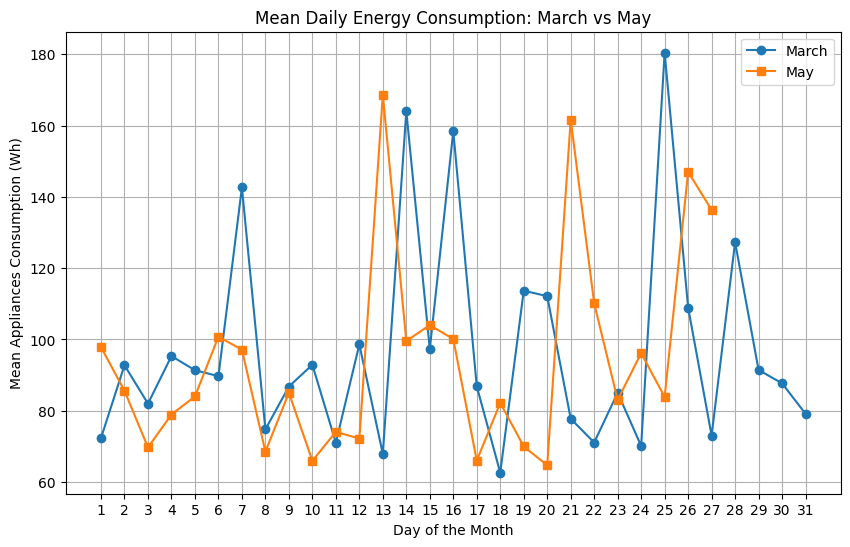

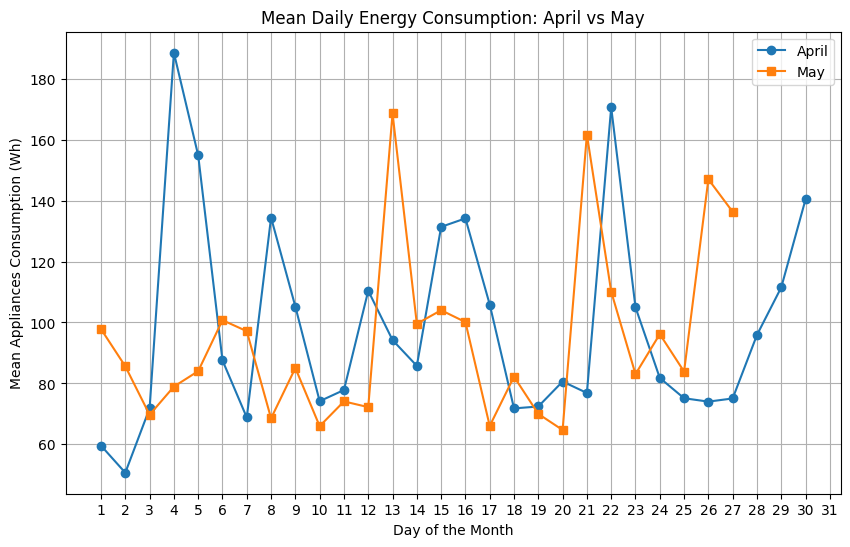

In [ ]:
import itertools
import matplotlib.pyplot as plt

def plot_monthly_combinations(data, target_column='Appliances'):

    data['month'] = data.index.month
    data['day'] = data.index.day

    month_names = ['January', 'February', 'March', 'April', 'May']
    months = [1, 2, 3, 4, 5]
    month_combinations = list(itertools.combinations(months, 2))

    # Compute the daily mean appliance consumption
    daily_mean = data.groupby(['month', 'day'])[target_column].mean().reset_index()

    # Plot each pair of months
    for combo in month_combinations:
        month1_mean = daily_mean[daily_mean['month'] == combo[0]]
        month2_mean = daily_mean[daily_mean['month'] == combo[1]]

        plt.figure(figsize=(10, 6))
        plt.plot(month1_mean['day'], month1_mean[target_column], label=month_names[combo[0] - 1], marker='o')
        plt.plot(month2_mean['day'], month2_mean[target_column], label=month_names[combo[1] - 1], marker='s')


        plt.legend()
        plt.xlabel("Day of the Month")
        plt.ylabel(f"Mean {target_column} Consumption (Wh)")
        plt.title(f"Mean Daily Energy Consumption: {month_names[combo[0] - 1]} vs {month_names[combo[1] - 1]}")
        plt.xticks(range(1, 32))
        plt.grid()
        plt.show()


plot_monthly_combinations(df, target_column='Appliances')

**Key Takeaways**

1. No Single Month Is Consistently Higher or Lower

* Instead, each month has “peaks” and “valleys” that can outdo or dip below the neighboring months on any given day.

2. High Spikes Are Likely Event‐ or Weather‐Driven

* For instance, a day of extra cooking, laundry, or heating/cooling could explain jumps to 160–180 Wh.

3. Dips Suggest Light Appliance Usage

* Possibly weekends away, partial occupancy, or unseasonably mild weather requiring neither heating nor cooling.


**Observations and Insights from the Plots:**

 * February, March, and April exhibit relatively flatter patterns, with fewer spikes.

 * Significant peaks occur on specific days (e.g., the 14th, 20th, 28th). These might correspond to higher activity levels or events.

 * The recurring lower consumption values indicate daily downtime, possibly nighttime or periods of inactivity.

 * April appears the most consistent, with fewer high peaks and steadier daily energy consumption. This could indicate a shift away from heating or significant appliance use.

In [ ]:
df.columns

Index(['Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4',
       'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9',
       'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility',
       'Tdewpoint', 'month', 'day'],
      dtype='object')

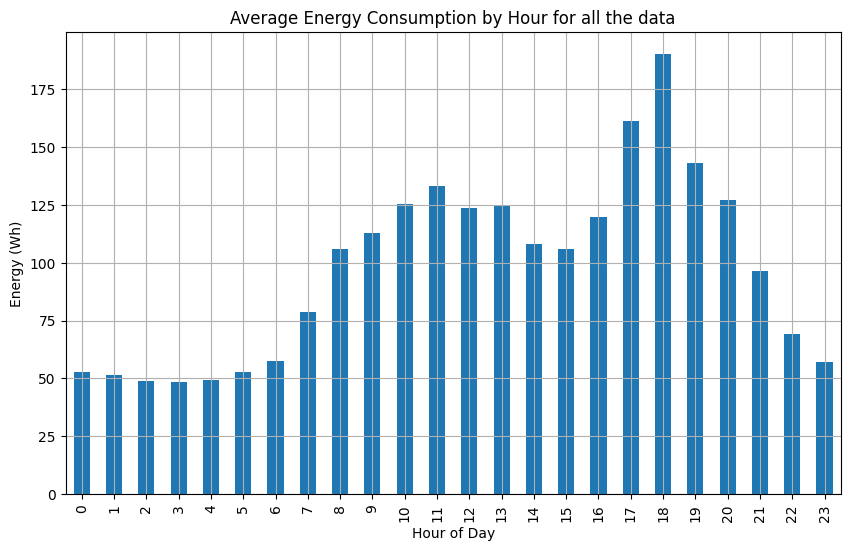

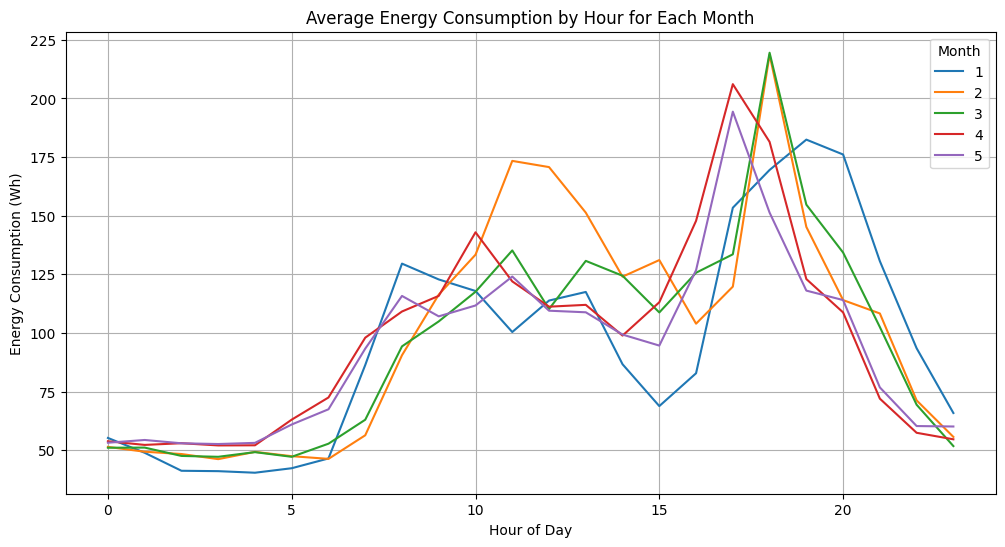

In [ ]:
df['hour'] = df.index.hour
df['minute'] = df.index.minute

# Plotting hourly energy consumption
hourly_avg = df.groupby('hour')['Appliances'].mean()

plt.figure(figsize=(10, 6))
hourly_avg.plot(kind='bar', title="Average Energy Consumption by Hour for all the data", ylabel="Energy (Wh)", xlabel="Hour of Day")
plt.grid()
plt.show()

hourly_avg_per_month = df.groupby(['month', 'hour'])['Appliances'].mean().unstack(level=0)

hourly_avg_per_month.plot(figsize=(12, 6), title="Average Energy Consumption by Hour for Each Month")
plt.xlabel("Hour of Day")
plt.ylabel("Energy Consumption (Wh)")
plt.legend(title="Month", loc="upper right")
plt.grid()
plt.show()

**Insights from the Plots:**

1. **Average Energy Consumption by Hour for All Train Data**

-> Peaks and Valleys:

 * Energy consumption remains relatively low during early morning hours (12 AM to 6 AM), likely reflecting minimal activity or sleeping hours.

 * A gradual increase starts after 6 AM, with a significant peak at around 6 PM (18:00), possibly due to evening activities like cooking, heating, and lighting.

 * Energy usage starts decreasing after 8 PM (20:00) and levels off as night approaches.

-> Key Takeaway:

 * This suggests clear daily routines in energy usage. Morning and evening peaks align with typical residential behavior.
 -----------

2. **Average Energy Consumption by Hour for Each Month
Comparison Across Months:**

-> January (1):
 * Lower consumption during early morning hours (12 AM to 6 AM), with a gradual increase peaking at around 6 PM (18:00).

->February (2) and March (3):
* Follow a similar trend, but February exhibits slightly higher evening peaks, suggesting more appliance usage during colder periods.

->Morning Routines:

 * Energy consumption in the morning hours (6 AM to 10 AM) is more uniform across all months, likely reflecting consistent daily activities like preparing for work or school.
-------------

3. Combined Observations:

->Evening Peaks Dominate:

 * Across all months, energy consumption peaks in the evening, suggesting that residential activities heavily influence energy use during these hours.

->Consistent Off-Peak Patterns:

 * Early morning (12 AM to 6 AM) and late evening hours (9 PM onward) show consistently low consumption, likely due to minimal residential activity.

In [ ]:
df.head(3)

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,month,day,hour,minute
date,,,,,,,,,,,,,,,,,,,,,
2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,6.600000,733.5,92.0,7.000000,63.000000,5.3,1,11,17,0
2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,6.483333,733.6,92.0,6.666667,59.166667,5.2,1,11,17,10
2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,6.366667,733.7,92.0,6.333333,55.333333,5.1,1,11,17,20


In [ ]:
df.dtypes

,0
Appliances,int64
lights,int64
T1,float64
RH_1,float64
T2,float64
RH_2,float64
T3,float64
RH_3,float64
T4,float64
RH_4,float64


In [ ]:
df['day_of_week'] = df.index.dayofweek  # 0=Monday, 6=Sunday
df['is_weekend'] = df['day_of_week'].isin([5, 6])  # True if Saturday (5) or Sunday (6)

In [ ]:
df.columns

Index(['Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4',
       'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9',
       'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility',
       'Tdewpoint', 'month', 'day', 'hour', 'minute', 'day_of_week',
       'is_weekend'],
      dtype='object')

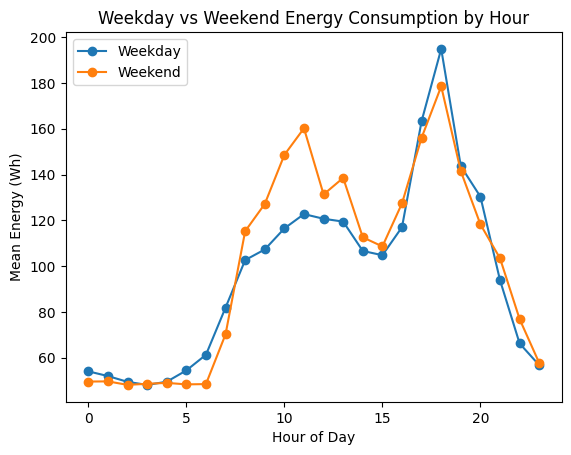

In [ ]:
import matplotlib.pyplot as plt

df_weekday = df[df['is_weekend'] == False]
df_weekend = df[df['is_weekend'] == True]


weekday_hourly = df_weekday.groupby('hour')['Appliances'].mean()
weekend_hourly = df_weekend.groupby('hour')['Appliances'].mean()
hourly_comparison = df.groupby(['is_weekend', 'hour'])['Appliances'].mean().reset_index()


hourly_pivot = hourly_comparison.pivot(
    index='hour',
    columns='is_weekend',
    values='Appliances'
)


plt.plot(hourly_pivot.index, hourly_pivot[False], label='Weekday', marker='o')
plt.plot(hourly_pivot.index, hourly_pivot[True], label='Weekend', marker='o')
plt.xlabel('Hour of Day')
plt.ylabel('Mean Energy (Wh)')
plt.title('Weekday vs Weekend Energy Consumption by Hour')
plt.legend()
plt.show()

We observe that on the weekends we have a steep flactuation in the morning indicating that the occupants start their routine or chores earlier. As for the evening hours, they energy usage is pretty much the same.

## We observed that 30d avg is constant

In [ ]:
# hourly avg
df['1h_rolling_avg'] = df['Appliances'].rolling(window=60).mean()

# 6 hours avg
df['6h_rolling_avg'] = df['Appliances'].rolling(window=360).mean()

# 1 day avg
df['1d_rolling_avg'] = df['Appliances'].rolling(window=144).mean()

# 7 days avg
df['7d_rolling_avg'] = df['Appliances'].rolling(window=7*144).mean()


# Plotting the rolling averages together for comparison
plt.figure(figsize=(12, 6))
plt.plot(df['Appliances'], alpha=0.3, label='Raw Data', color='blue')
plt.plot(df['1h_rolling_avg'], label='1-Hour Rolling Average', color='orange')
plt.plot(df['6h_rolling_avg'], label='6-Hours Rolling Average', color='red')
plt.plot(df['1d_rolling_avg'], label='1-Day Rolling Average', color='green')
plt.plot(df['7d_rolling_avg'], label='7-Day Rolling Average', color='purple')

# Adding labels and title
plt.title("Energy Consumption with Multiple Rolling Averages (Training Set)")
plt.xlabel("Date")
plt.ylabel("Energy (Wh)")
plt.legend()
plt.grid()
plt.show()



import plotly.express as px
import plotly.graph_objects as go

# Create the figure
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=df.index,
    y=df['1h_rolling_avg'],
    mode='lines',
    name='1-Day Rolling Average'
))

fig.add_trace(go.Scatter(
    x=df.index,
    y=df['6h_rolling_avg'],
    mode='lines',
    name='6-hours Rolling Average'
))

fig.add_trace(go.Scatter(
    x=df.index,
    y=df['1d_rolling_avg'],
    mode='lines',
    name='1-Day Rolling Average'
))

fig.add_trace(go.Scatter(
    x=df.index,
    y=df['7d_rolling_avg'],
    mode='lines',
    name='7-Day Rolling Average'
))

# Add a title and configure range slider
fig.update_layout(
    title='Appliances Energy Consumption with Rolling Averages',
    xaxis=dict(
        rangeslider=dict(visible=True),
        rangeselector=dict(
            buttons=[
                dict(step='all', label='All'),
            ]
        )
    ),
    yaxis_title="Energy Consumption (Wh)",
    xaxis_title="Date",
)

# Show the figure
fig.show()


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
df.head(3)

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,month,day,minute,hour,day_of_week,is_weekend,1h_rolling_avg,6h_rolling_avg,1d_rolling_avg,7d_rolling_avg
date,,,,,,,,,,,,,,,,,,,,,
2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,1,11,0,17,0,False,NaN,NaN,NaN,NaN
2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,1,11,10,17,0,False,NaN,NaN,NaN,NaN
2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,1,11,20,17,0,False,NaN,NaN,NaN,NaN


In [ ]:
from statsmodels.tsa.stattools import adfuller

# Perform ADF test
result = adfuller(df['Appliances'])
print('ADF Statistic:', result[0])
print('p-value:', result[1])
print('Critical Values:', result[4])

ADF Statistic: -21.6163781980362
p-value: 0.0
Critical Values: {'1%': -3.430681600227742, '5%': -2.8616865555329394, '10%': -2.566848007525354}


## TEST RESULTS
The time series is stationary.
It does not have a unit root, meaning its mean and variance are constant over time, and it is suitable for models that assume stationarity (e.g., ARIMA).

### SEASONAL DECOMPOSITION

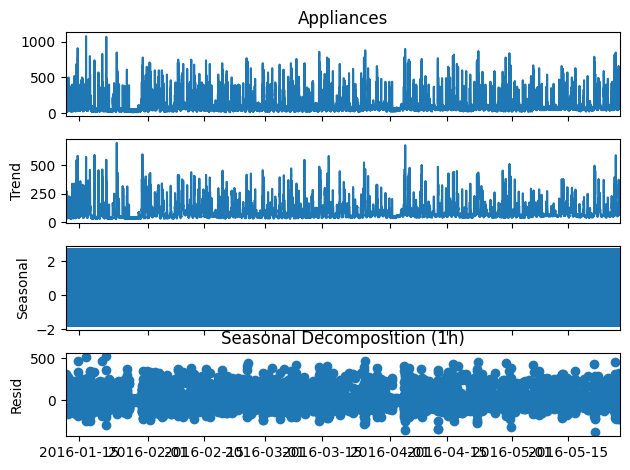

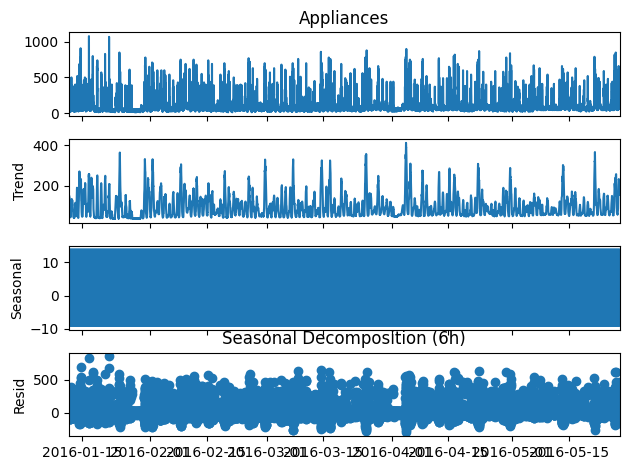

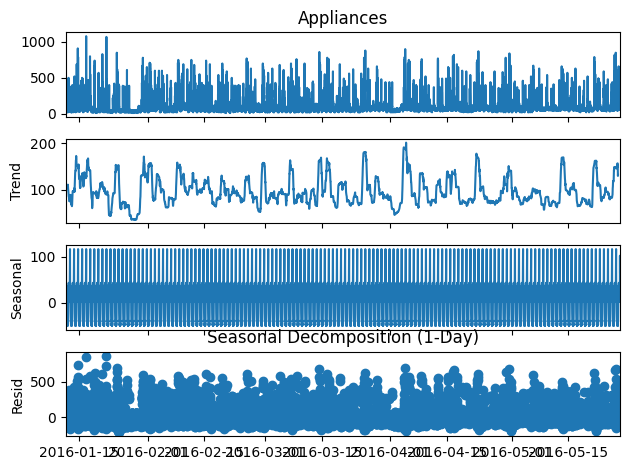

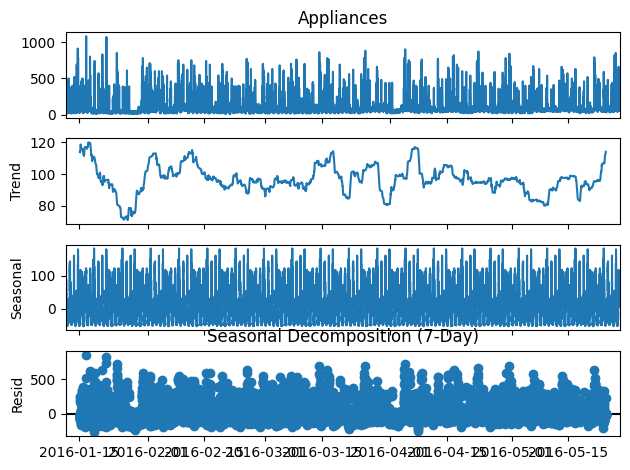

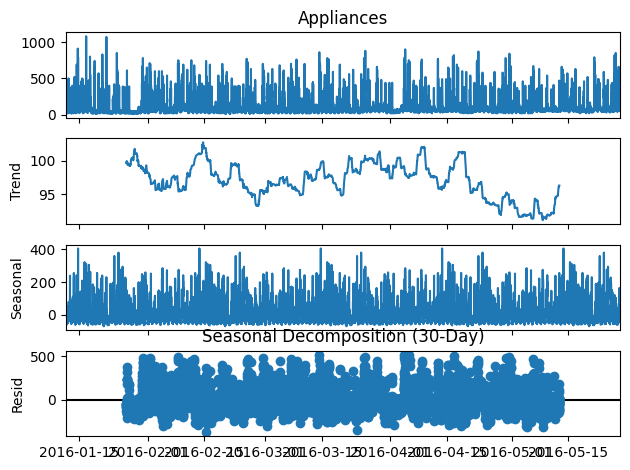

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

result_1h = seasonal_decompose(df['Appliances'], model='additive', period= 6)
result_6h = seasonal_decompose(df['Appliances'], model='additive', period= 36)
result_1d = seasonal_decompose(df['Appliances'], model='additive', period= 144)
result_7d = seasonal_decompose(df['Appliances'], model='additive', period= 7*144)
result_30d = seasonal_decompose(df['Appliances'], model='additive', period= 30*144)
result_1h.plot()
plt.title("Seasonal Decomposition (1h)")
plt.show()
result_6h.plot()
plt.title("Seasonal Decomposition (6h)")
plt.show()
result_1d.plot()
plt.title("Seasonal Decomposition (1-Day)")
plt.show()
result_7d.plot()
plt.title("Seasonal Decomposition (7-Day)")
plt.show()
result_30d.plot()
plt.title("Seasonal Decomposition (30-Day)")
plt.show()

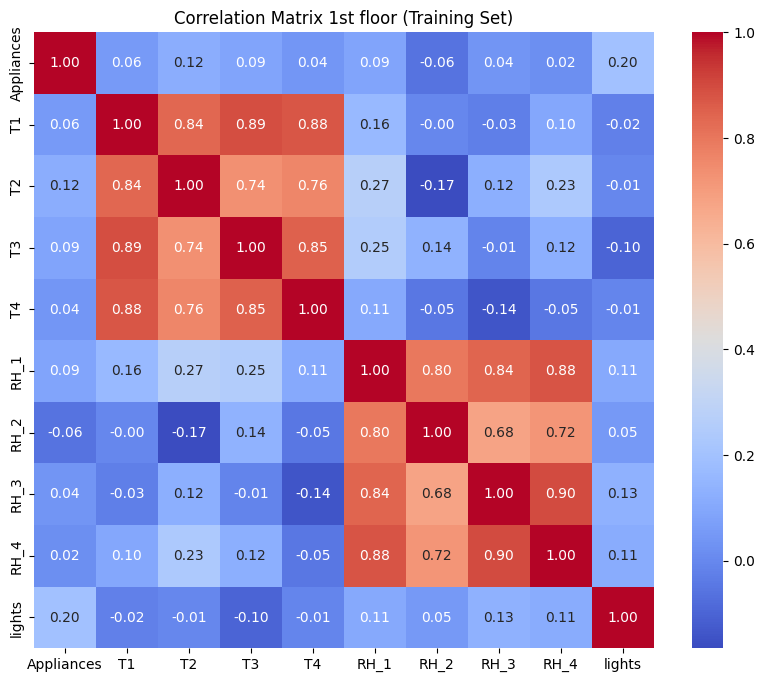

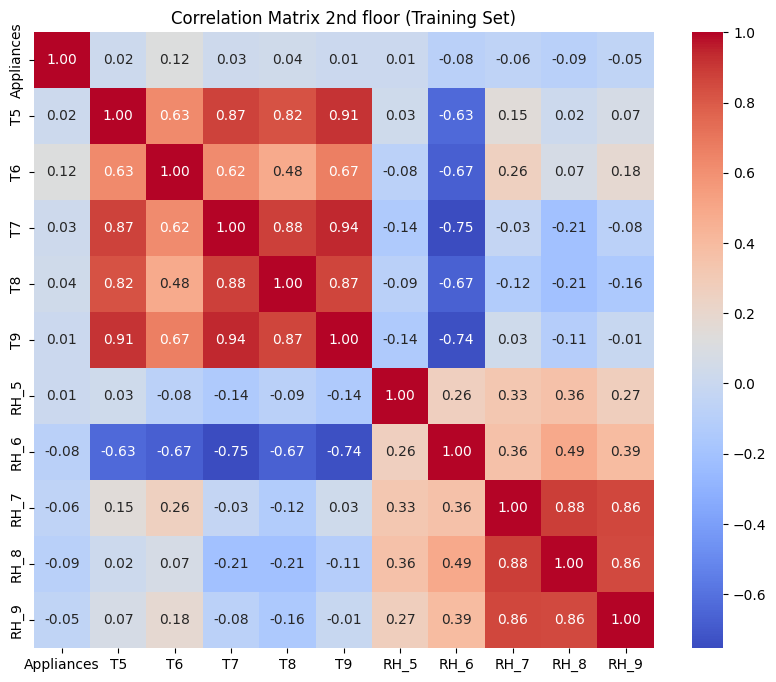

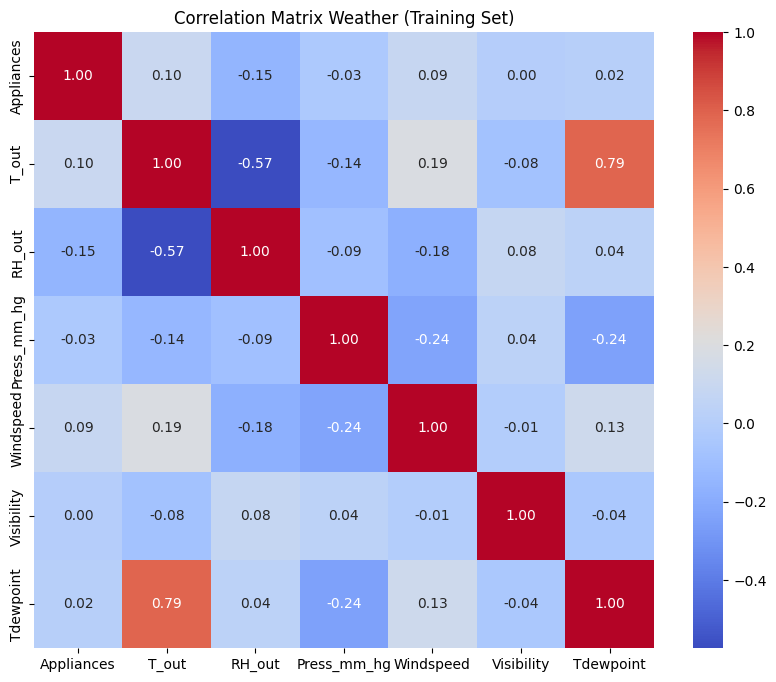

In [ ]:
plt.figure(figsize=(10, 8))
corr_1st_floor = df[['Appliances', 'T1', 'T2', 'T3', 'T4', 'RH_1', 'RH_2', 'RH_3', 'RH_4', 'lights']].corr()
sns.heatmap(corr_1st_floor, annot=True, cmap="coolwarm", fmt=".2f", cbar=True)
plt.title("Correlation Matrix 1st floor (Training Set)")
plt.show()

plt.figure(figsize=(10, 8))
corr_2nd_floor = df[['Appliances', 'T5', 'T6', 'T7', 'T8', 'T9', 'RH_5', 'RH_6', 'RH_7', 'RH_8', 'RH_9']].corr()
sns.heatmap(corr_2nd_floor, annot=True, cmap="coolwarm", fmt=".2f", cbar=True)
plt.title("Correlation Matrix 2nd floor (Training Set)")
plt.show()

plt.figure(figsize=(10, 8))
corr_weather = df[['Appliances', 'T_out', 'RH_out', 'Press_mm_hg', 'Windspeed', 'Visibility', 'Tdewpoint']].corr()
sns.heatmap(corr_weather, annot=True, cmap="coolwarm", fmt=".2f", cbar=True)
plt.title("Correlation Matrix Weather (Training Set)")
plt.show()

-------------------

Removed weak correlation features: ['T7', 'T5', 'is_weekend', 'RH_4', 'Tdewpoint', 'minute', '7d_rolling_avg', 'month', 'T9', 'RH_5', 'day_of_week', 'day', 'Visibility']
Dropped highly correlated features: {'RH_9', 'T_out', 'RH_3', 'T8', 'T4', 'RH_7', 'T6', 'T1'}
Final selected features: ['Appliances', 'lights', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_6', 'RH_8', 'Press_mm_hg', 'RH_out', 'Windspeed', 'hour', '1h_rolling_avg', '6h_rolling_avg', '1d_rolling_avg']


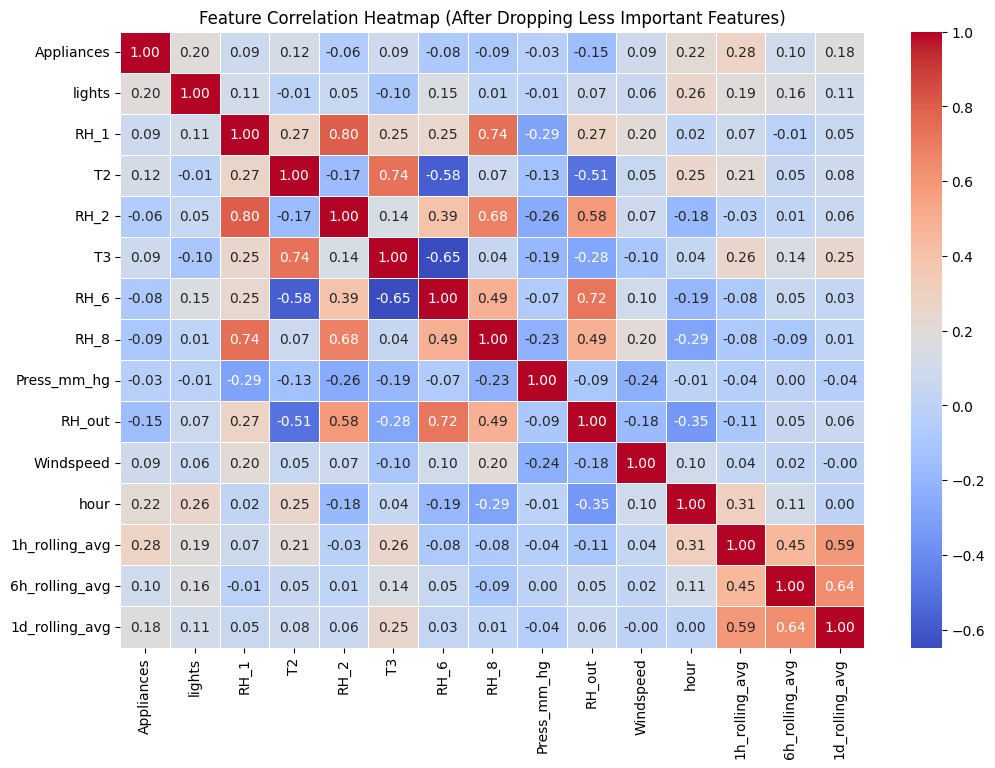

In [ ]:
df_copied = df.copy()
if 'date' in df_copied.columns:
    df_copied.drop(columns=['date'], inplace=True)

correlation_matrix = df_copied.corr()

corr_with_target = correlation_matrix["Appliances"].abs().sort_values(ascending=False)

highly_corr_features = corr_with_target[corr_with_target > 0.03].index.tolist()
weak_corr_features = corr_with_target[corr_with_target < 0.03].index.tolist()


df_copied.drop(columns=weak_corr_features, inplace=True)
print(f"Removed weak correlation features: {weak_corr_features}")

# Upgrade the matrix
correlation_matrix = df_copied.corr()

corr_threshold = 0.8
high_corr_pairs = set()


for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > corr_threshold:
            feature_1 = correlation_matrix.columns[i]
            feature_2 = correlation_matrix.columns[j]


            if corr_with_target[feature_1] > corr_with_target[feature_2]:
                high_corr_pairs.add(feature_2)
            else:
                high_corr_pairs.add(feature_1)


df_copied.drop(columns=high_corr_pairs, inplace=True)
print(f"Dropped highly correlated features: {high_corr_pairs}")

print(f"Final selected features: {list(df_copied.columns)}")

plt.figure(figsize=(12, 8))
sns.heatmap(df_copied.corr(), annot=True, cmap="coolwarm", fmt='.2f' , linewidths=0.5)
plt.title("Feature Correlation Heatmap (After Dropping Less Important Features)")
plt.show()

In [ ]:
import numpy as np

# Lag Features (Using past values of the most correlated features with Appliances)
lag_features = ['Appliances', 'lights', 'T2', 'RH_out']
for col in lag_features:
    df_copied[f"{col}_lag_1"] = df_copied[col].shift(1)
    df_copied[f"{col}_lag_3"] = df_copied[col].shift(3)

# Rolling Averages (Smoothing short-term fluctuations for all the features)
rolling_features = ['Appliances', 'T2', 'RH_8', 'Press_mm_hg', 'RH_out', 'Windspeed', 'lights']
for col in rolling_features:
    df_copied[f"{col}_rolling_3"] = df_copied[col].rolling(window=3).mean()
    df_copied[f"{col}_rolling_6"] = df_copied[col].rolling(window=6).mean()


# Convert time-based features into cyclical features (sin & cos transformation)
df_copied['hour_sin'] = np.sin(2 * np.pi * df_copied['hour'] / 24)
df_copied['hour_cos'] = np.cos(2 * np.pi * df_copied['hour'] / 24)

# Dropping the NaN values
max_na_cutoff = max(3, 6)  # The longest rolling window or lag (6)
df_copied = df_copied.iloc[max_na_cutoff:]  # Drop only first few NaN rows

# Drop raw time-based categorical columns after transformation
df_copied.drop(columns=['hour'], inplace=True)
df_copied.head(2)

<ipython-input-96-8a70555eeefd>:25: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,Appliances,lights,RH_1,T2,RH_2,T3,RH_6,RH_8,Press_mm_hg,RH_out,...,Press_mm_hg_rolling_3,Press_mm_hg_rolling_6,RH_out_rolling_3,RH_out_rolling_6,Windspeed_rolling_3,Windspeed_rolling_6,lights_rolling_3,lights_rolling_6,hour_sin,hour_cos
date,,,,,,,,,,,,,,,,,,,,,
2016-01-11 20:00:00,80,30,51.193333,20.2,46.330000,20.200000,86.760000,50.20,735.200000,88.000000,...,735.083333,734.908333,88.500000,89.250000,6.0,6.0,23.333333,21.666667,-0.866025,0.5
2016-01-11 20:10:00,140,40,49.800000,20.2,46.026667,20.166667,87.463333,50.26,735.233333,87.833333,...,735.172222,735.011111,88.111111,88.805556,6.0,6.0,33.333333,21.666667,-0.866025,0.5


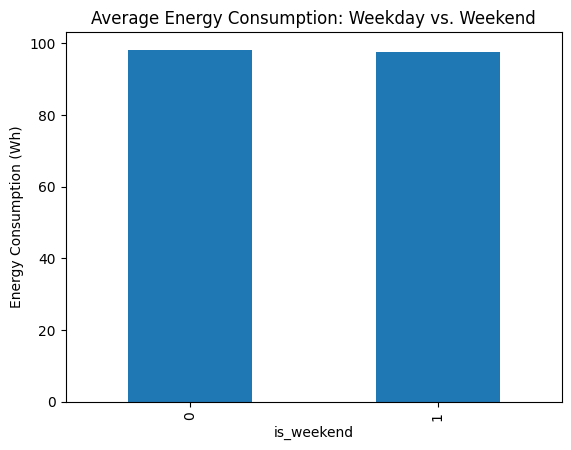

In [ ]:
train_data2['is_weekend'] = train_data2.index.weekday.isin([5, 6]).astype(int)

train_data2.groupby('is_weekend')['Appliances'].mean().plot(kind='bar', title='Average Energy Consumption: Weekday vs. Weekend')
plt.ylabel('Energy Consumption (Wh)')
plt.show()

The plot shows that the average energy consumption on weekdays and weekends is nearly the same. This indicates that the is_weekend feature might not significantly influence Appliances energy consumption, but it can still be retained for model training to confirm its importance through feature selection or importance analysis (e.g., using SHAP or feature importance from XGBoost).

### Outlier Detection

In [ ]:
import pandas as pd
from google.colab import drive

drive.mount('/content/drive', force_remount=True)
file_path = '/content/drive/MyDrive/Machine_Learning/Final_Project/energydata_reviewed.csv'
df = pd.read_csv(file_path)

Mounted at /content/drive


In [ ]:
df['date'] = pd.to_datetime(df['date'])
df.set_index('date', inplace=True)

<ipython-input-5-9548244f7662>:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(df.values, vert=False, labels=df.columns)


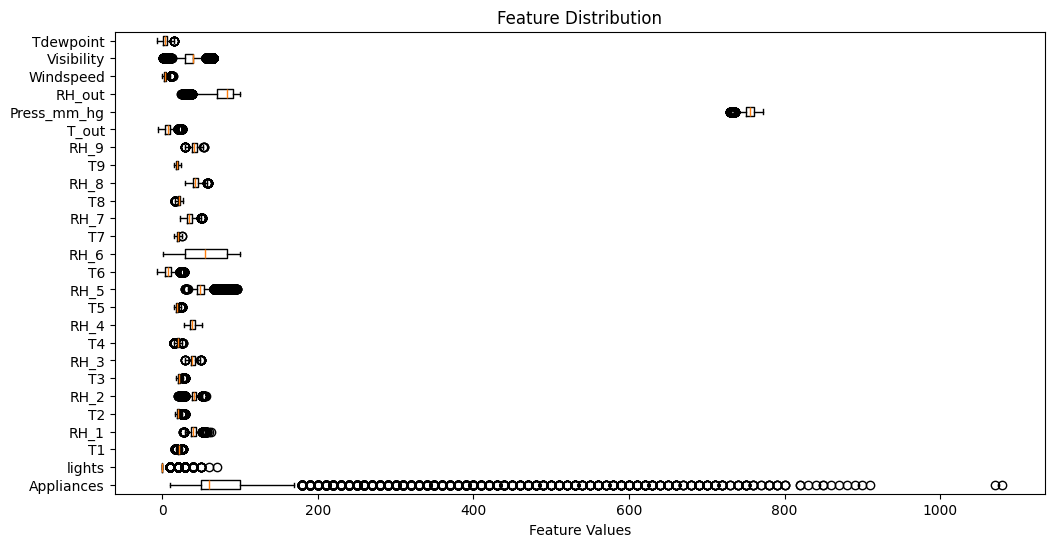

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.boxplot(df.values, vert=False, labels=df.columns)
plt.title("Feature Distribution")
plt.xlabel("Feature Values")
plt.show()

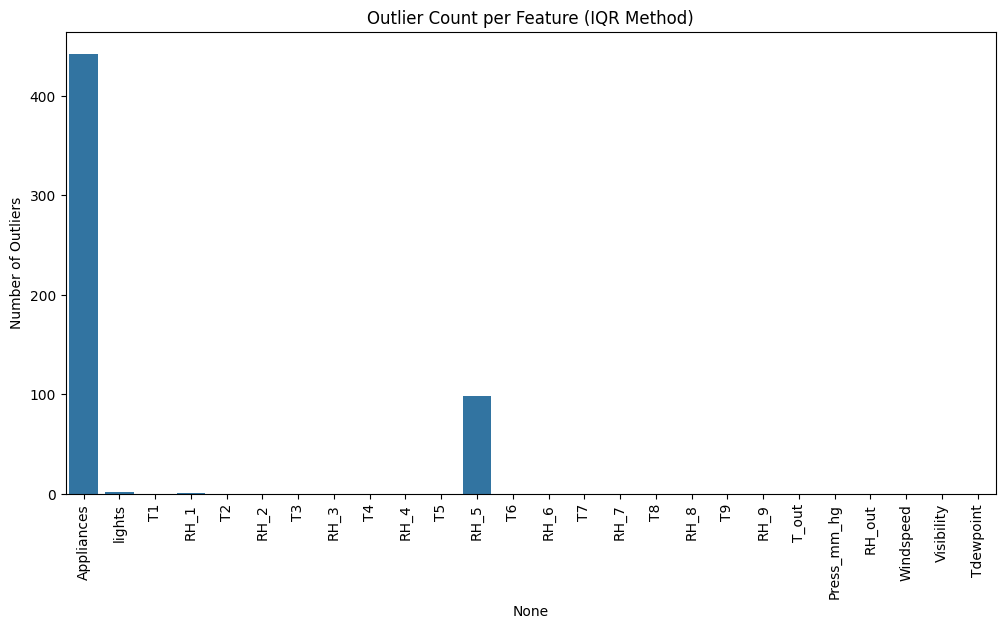

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

Q1 = df.quantile(0.1)
Q3 = df.quantile(0.9)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = ((df < lower_bound) | (df > upper_bound)).sum()

plt.figure(figsize=(12, 6))
sns.barplot(x=outlier_counts.index, y=outlier_counts.values)
plt.xticks(rotation=90)
plt.ylabel("Number of Outliers")
plt.title("Outlier Count per Feature (IQR Method)")
plt.show()

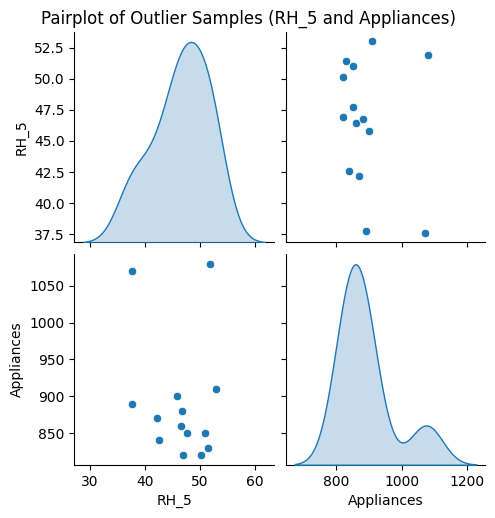

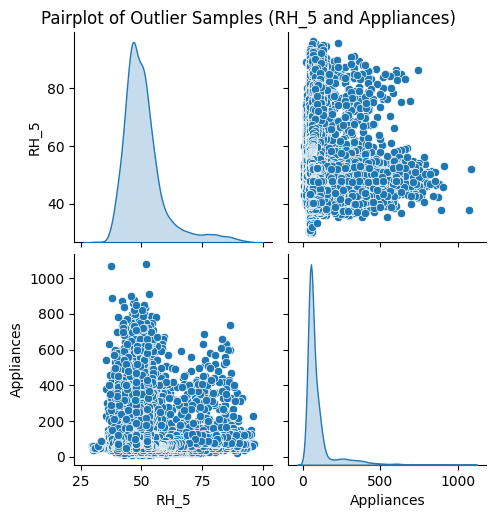

In [ ]:
sns.pairplot(df[(df['Appliances'] > 800)][['RH_5', 'Appliances']], diag_kind='kde')
plt.suptitle("Pairplot of Outlier Samples (RH_5 and Appliances)", y=1.02)
plt.show()
sns.pairplot(df[['RH_5', 'Appliances']], diag_kind='kde')
plt.suptitle("Pairplot of Outlier Samples (RH_5 and Appliances)", y=1.02)
plt.show()

The provided plot is quite interesting because the RH_5 is located in the bathroom where the humidity is very unstable. Also, it's impact in the total consumption is a bit constant with a bit negative correlation as indicated on the plots (usually for small RH_5 we see either small values of appliances or big values). Here, we can handle the outliers of the "Appliances" by using in the training set the cliping method where we replace the extreme values with the upper/lower bounds. As for the RH_5, we can leave it as it is because we can't ensure exclucively huge or small predictions.